## steps to build a ml model

# 1. data gathering
# 2. import all libararies
# 3. Data exploration
# 4. data cleaning --- isnull()

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import sklearn

In [3]:
df=pd.read_csv('Education.csv')

## data exploration

In [4]:
df.head()

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate
0,USA,Cambridge,Harvard University,Computer Science,Master,2.0,55400,83.5,2200,160,1500,1.00
1,UK,London,Imperial College London,Data Science,Master,1.0,41200,75.8,1800,485,800,0.79
2,Canada,Toronto,University of Toronto,Business Analytics,Master,2.0,38500,72.5,1600,235,900,1.35
3,Australia,Melbourne,University of Melbourne,Engineering,Master,2.0,42000,71.2,1400,450,650,1.52
4,Germany,Munich,Technical University of Munich,Mechanical Engineering,Master,2.0,500,70.5,1100,75,550,0.92


In [5]:
df.sample(5)

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate
600,Austria,Leoben,Montanuniversität Leoben,Industrial Engineering,PhD,4.0,1500,68.7,700,160,850,0.92
257,UK,Essex,University of Essex,Computer Science,Bachelor,3.0,26500,69.8,1000,490,800,0.79
808,Kuwait,Kuwait City,Kuwait University,Data Science,Master,2.0,3500,71.2,800,140,700,0.31
809,Ukraine,Kyiv,Igor Sikorsky Kyiv Polytechnic,Software Engineering,Bachelor,4.0,3800,45.8,400,120,300,36.80
444,Germany,Aachen,RWTH Aachen,Computer Science,Bachelor,3.0,0,68.9,1000,110,900,0.92


In [6]:
df.describe()

,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate
count,907.000000,907.000000,907.000000,907.000000,907.000000,907.000000,907.000000
mean,2.836825,16705.016538,64.437486,969.206174,211.396913,700.077178,623.000695
std,0.945449,16582.385275,14.056333,517.154752,143.435740,320.374875,3801.746134
min,1.000000,0.000000,27.800000,150.000000,40.000000,200.000000,0.150000
25%,2.000000,2850.000000,56.300000,545.000000,100.000000,450.000000,0.920000
50%,3.000000,7500.000000,67.500000,900.000000,160.000000,650.000000,1.350000
75%,4.000000,31100.000000,72.200000,1300.000000,240.000000,800.000000,7.150000
max,5.000000,62000.000000,122.400000,2500.000000,490.000000,1500.000000,42150.000000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 907 entries, 0 to 906
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country            907 non-null    object 
 1   City               907 non-null    object 
 2   University         907 non-null    object 
 3   Program            907 non-null    object 
 4   Level              907 non-null    object 
 5   Duration_Years     907 non-null    float64
 6   Tuition_USD        907 non-null    int64  
 7   Living_Cost_Index  907 non-null    float64
 8   Rent_USD           907 non-null    int64  
 9   Visa_Fee_USD       907 non-null    int64  
 10  Insurance_USD      907 non-null    int64  
 11  Exchange_Rate      907 non-null    float64
dtypes: float64(3), int64(4), object(5)
memory usage: 85.2+ KB


In [8]:
df.shape

(907, 12)

In [9]:
df.size

10884

In [10]:
df.dtypes

Country               object
City                  object
University            object
Program               object
Level                 object
Duration_Years       float64
Tuition_USD            int64
Living_Cost_Index    float64
Rent_USD               int64
Visa_Fee_USD           int64
Insurance_USD          int64
Exchange_Rate        float64
dtype: object

In [11]:
df['Country'].value_counts()

Country
UK                93
Australia         86
USA               78
Canada            76
Germany           33
                  ..
Nigeria            1
Israel             1
Taiwan             1
South Africa       1
Czech Republic     1
Name: count, Length: 71, dtype: int64

In [12]:
df['Country'].unique()

array(['USA', 'UK', 'Canada', 'Australia', 'Germany', 'Japan',
       'Netherlands', 'Singapore', 'France', 'Switzerland', 'Sweden',
       'Denmark', 'China', 'South Korea', 'Ireland', 'New Zealand',
       'Austria', 'Belgium', 'Hong Kong', 'Portugal', 'Israel', 'Taiwan',
       'Czech Republic', 'India', 'Poland', 'Malaysia', 'Spain', 'Italy',
       'Finland', 'Norway', 'Brazil', 'Turkey', 'Russia', 'Mexico',
       'Greece', 'Thailand', 'UAE', 'South Africa', 'Egypt', 'Argentina',
       'Indonesia', 'Saudi Arabia', 'Nigeria', 'Vietnam', 'Hungary',
       'Iceland', 'Colombia', 'Romania', 'Luxembourg', 'Tunisia',
       'Cyprus', 'Croatia', 'Dominican Republic', 'Morocco', 'Peru',
       'Ecuador', 'Lebanon', 'Bahrain', 'Uruguay', 'Bulgaria', 'Ghana',
       'Algeria', 'Panama', 'Bangladesh', 'Kuwait', 'Ukraine', 'Slovenia',
       'Serbia', 'Iran', 'Uzbekistan', 'El Salvador'], dtype=object)

In [13]:
df[df['Country']=='India']

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate
44,India,Bangalore,Indian Institute of Science,Computer Science,Master,2.0,2500,45.6,500,200,300,83.20
648,India,Bangalore,Indian Institute of Science,Data Science,PhD,4.0,2000,45.2,300,180,300,82.75
654,India,Mumbai,IIT Bombay,Computer Engineering,Master,2.0,1800,47.5,350,180,300,82.75
659,India,Delhi,IIT Delhi,Artificial Intelligence,PhD,4.0,1900,44.8,320,180,300,82.75
665,India,Chennai,IIT Madras,Software Engineering,Master,2.0,1700,42.4,280,180,300,82.75
671,India,Hyderabad,IIT Hyderabad,Data Analytics,PhD,4.0,1800,41.2,260,180,300,82.75
677,India,Pune,IIT Pune,Computer Science,Master,2.0,1600,40.5,250,180,300,82.75
683,India,Kanpur,IIT Kanpur,Artificial Intelligence,PhD,4.0,1900,39.8,240,180,300,82.75


In [14]:
df.columns

Index(['Country', 'City', 'University', 'Program', 'Level', 'Duration_Years',
       'Tuition_USD', 'Living_Cost_Index', 'Rent_USD', 'Visa_Fee_USD',
       'Insurance_USD', 'Exchange_Rate'],
      dtype='object')

In [15]:
df['City'].value_counts()

City
Singapore     18
Melbourne     11
Sydney        11
London        10
Canberra       8
              ..
Porto          1
Uppsala        1
Wellington     1
Herning        1
Al-Ahsa        1
Name: count, Length: 556, dtype: int64

In [16]:
df['Program'].value_counts()

Program
Computer Science           312
Data Science                82
Computer Engineering        71
Software Engineering        57
Artificial Intelligence     53
                          ... 
Technology & Innovation      1
Computing & Innovation       1
Digital Systems & AI         1
Business Informatics         1
Data Systems                 1
Name: count, Length: 92, dtype: int64

In [17]:
df['Level'].value_counts()

Level
Master      451
Bachelor    297
PhD         159
Name: count, dtype: int64

In [18]:
df['Duration_Years'].value_counts()

Duration_Years
2.0    423
4.0    276
3.0    171
5.0     17
1.0     16
2.5      3
1.5      1
Name: count, dtype: int64

## usinf isnull() function to findout any missing value

In [19]:
df.isnull().sum()

Country              0
City                 0
University           0
Program              0
Level                0
Duration_Years       0
Tuition_USD          0
Living_Cost_Index    0
Rent_USD             0
Visa_Fee_USD         0
Insurance_USD        0
Exchange_Rate        0
dtype: int64

In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
df['Duration_Years']=df['Duration_Years'].astype('float32')

In [22]:
df['Tuition_USD']=df['Tuition_USD'].astype('int32')


In [23]:
df['Rent_USD']=df['Rent_USD'].astype('int32')
df['Visa_Fee_USD']=df['Visa_Fee_USD'].astype('int32')
df['Insurance_USD']=df['Insurance_USD'].astype('int32')

In [24]:
df.dtypes

Country               object
City                  object
University            object
Program               object
Level                 object
Duration_Years       float32
Tuition_USD            int32
Living_Cost_Index    float64
Rent_USD               int32
Visa_Fee_USD           int32
Insurance_USD          int32
Exchange_Rate        float64
dtype: object

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 907 entries, 0 to 906
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country            907 non-null    object 
 1   City               907 non-null    object 
 2   University         907 non-null    object 
 3   Program            907 non-null    object 
 4   Level              907 non-null    object 
 5   Duration_Years     907 non-null    float32
 6   Tuition_USD        907 non-null    int32  
 7   Living_Cost_Index  907 non-null    float64
 8   Rent_USD           907 non-null    int32  
 9   Visa_Fee_USD       907 non-null    int32  
 10  Insurance_USD      907 non-null    int32  
 11  Exchange_Rate      907 non-null    float64
dtypes: float32(1), float64(2), int32(4), object(5)
memory usage: 67.4+ KB


In [26]:
df['Rent_USD']=df['Rent_USD'].astype('int32')

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 907 entries, 0 to 906
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country            907 non-null    object 
 1   City               907 non-null    object 
 2   University         907 non-null    object 
 3   Program            907 non-null    object 
 4   Level              907 non-null    object 
 5   Duration_Years     907 non-null    float32
 6   Tuition_USD        907 non-null    int32  
 7   Living_Cost_Index  907 non-null    float64
 8   Rent_USD           907 non-null    int32  
 9   Visa_Fee_USD       907 non-null    int32  
 10  Insurance_USD      907 non-null    int32  
 11  Exchange_Rate      907 non-null    float64
dtypes: float32(1), float64(2), int32(4), object(5)
memory usage: 67.4+ KB


## EDA ---- explore single columns or multiple columns together

In [28]:
df['Country'].value_counts().head(10)

Country
UK             93
Australia      86
USA            78
Canada         76
Germany        33
France         27
South Korea    23
Netherlands    21
Switzerland    20
Singapore      18
Name: count, dtype: int64

In [29]:
country=df[df['Country'].isin(['UK','Australia','USA','Canada','Germany','France','South Korea','Netherlands','Switzerland','Singapore'])]

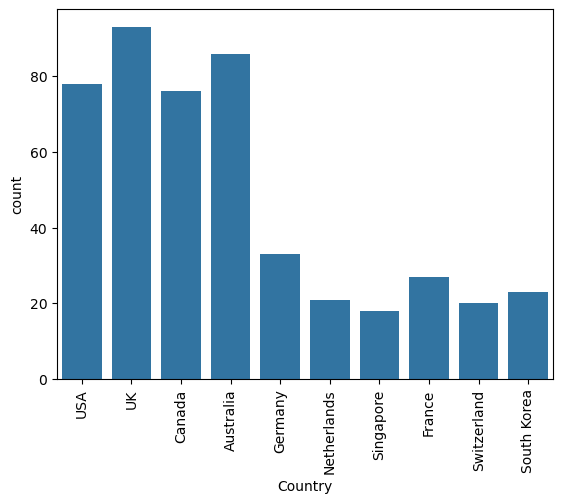

In [30]:
sns.countplot(data=country,x='Country')
plt.xticks(rotation='vertical')
plt.show()

In [31]:
df['City'].value_counts().head(5)

City
Singapore    18
Melbourne    11
Sydney       11
London       10
Canberra      8
Name: count, dtype: int64

In [32]:
city=df[df['City'].isin(['Singapore','Melbourne','Sydney','London','Canberra'])]

In [33]:
city

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate
1,UK,London,Imperial College London,Data Science,Master,1.0,41200,75.8,1800,485,800,0.79
3,Australia,Melbourne,University of Melbourne,Engineering,Master,2.0,42000,71.2,1400,450,650,1.52
7,Singapore,Singapore,National University of Singapore,Finance,Master,1.5,35000,81.1,1900,90,800,1.34
36,Singapore,Singapore,NTU Singapore,Data Science,PhD,4.0,8900,81.5,1600,90,800,1.34
38,Australia,Canberra,Australian National University,Climate Science,PhD,4.0,29800,70.2,1400,450,650,1.52
53,Australia,Sydney,University of Sydney,Business,Bachelor,3.0,35000,72.8,1600,450,650,1.52
101,UK,London,University College London,Computer Science,Master,1.0,39200,76.2,1900,485,800,0.79
151,Singapore,Singapore,Nanyang Technological University,Computer Science,Bachelor,4.0,32500,81.1,1500,90,800,1.34
152,Singapore,Singapore,Singapore Management University,Information Systems,Bachelor,4.0,31800,81.1,1500,90,800,1.34
153,Singapore,Singapore,SUTD,Computer Science & Design,Bachelor,4.0,31200,81.1,1500,90,800,1.34


<Axes: xlabel='Level', ylabel='count'>

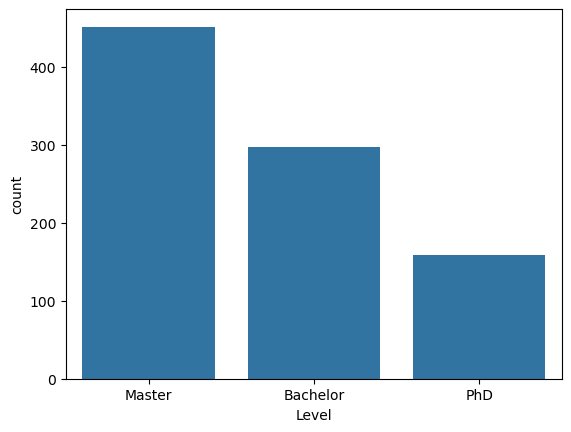

In [34]:
sns.countplot(data=df,x='Level')

In [35]:
df['Duration_Years'].value_counts()

Duration_Years
2.0    423
4.0    276
3.0    171
5.0     17
1.0     16
2.5      3
1.5      1
Name: count, dtype: int64

In [36]:
d1=df[df['Level']=='Master'].head(150)

In [37]:
d2=df[df['Level']=='Bachelor'].head(150)
d3=df[df['Level']=='PHD'].head(150)

In [38]:
d4=pd.concat([d1,d2,d3])

In [39]:
d4.shape

(300, 12)

<Axes: xlabel='Duration_Years', ylabel='Count'>

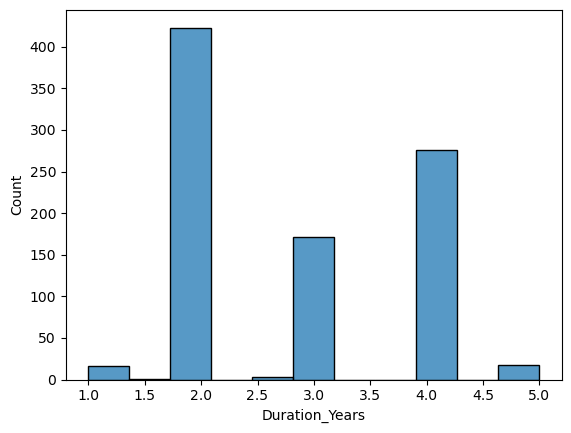

In [40]:
sns.histplot(data=df,x='Duration_Years')

<Axes: xlabel='Duration_Years', ylabel='Count'>

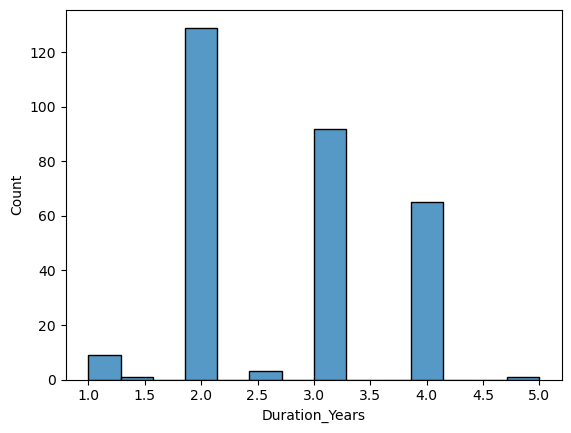

In [41]:
sns.histplot(data=d4,x='Duration_Years')

In [42]:
df.columns

Index(['Country', 'City', 'University', 'Program', 'Level', 'Duration_Years',
       'Tuition_USD', 'Living_Cost_Index', 'Rent_USD', 'Visa_Fee_USD',
       'Insurance_USD', 'Exchange_Rate'],
      dtype='object')

<Axes: xlabel='Tuition_USD', ylabel='Count'>

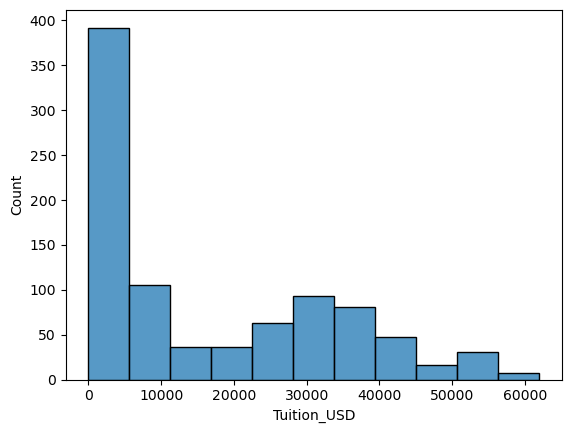

In [43]:
sns.histplot(data=df,x='Tuition_USD')

<Axes: xlabel='Rent_USD', ylabel='Count'>

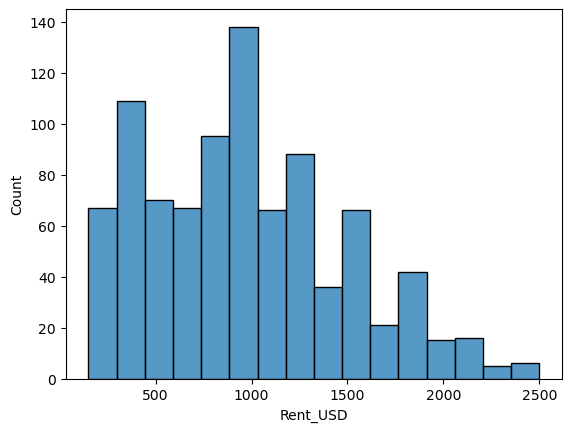

In [44]:
sns.histplot(data=df,x='Rent_USD')

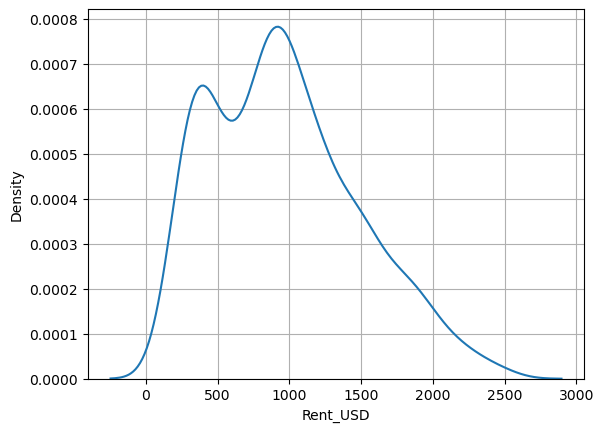

In [45]:
sns.kdeplot(data=df,x='Rent_USD')
plt.grid()

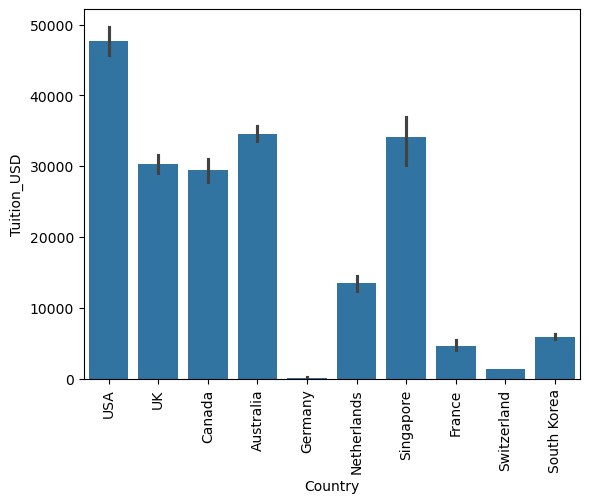

In [46]:
sns.barplot(data=country,x='Country',y='Tuition_USD')
plt.xticks(rotation='vertical')
plt.show()

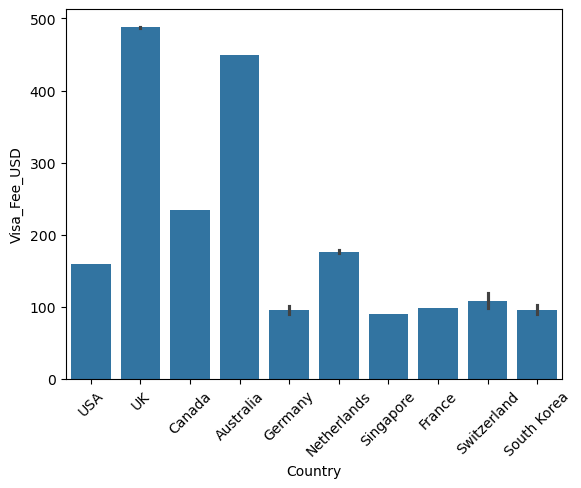

In [47]:
sns.barplot(data=country,x='Country',y='Visa_Fee_USD')
plt.xticks(rotation=45)
plt.show()

In [48]:
df['University'].value_counts().head(10)

University
University of Washington           6
University of Sydney               5
University of Tasmania             5
University of Wollongong           5
Australian National University     5
Griffith University                5
Stanford University                5
University of Western Australia    5
University of Adelaide             5
University of Newcastle            5
Name: count, dtype: int64

In [49]:
university=df[df['University'].isin(['University of Washington',      'University of Sydney',               
'University of Tasmania'            
'University of Wollongong',           
'Australian National University',     
'Griffith University',             
'Stanford University',             
'University of Western Australia',    
'University of Adelaide',             
'University of Newcastle'])]

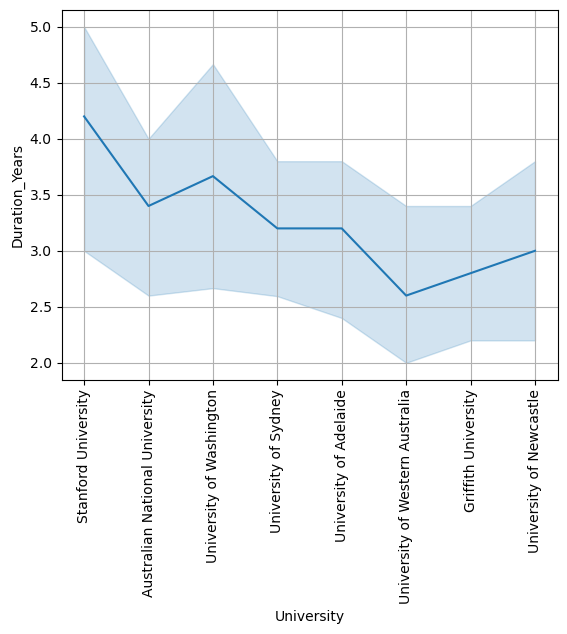

In [50]:
sns.lineplot(data=university,x='University',y='Duration_Years')
plt.xticks(rotation=90)
plt.grid()
plt.show()

In [51]:
country['Country'].value_counts().head(10)

Country
UK             93
Australia      86
USA            78
Canada         76
Germany        33
France         27
South Korea    23
Netherlands    21
Switzerland    20
Singapore      18
Name: count, dtype: int64

In [52]:
country['University'].value_counts().head(10)

University
University of Washington           6
Australian National University     5
University of Melbourne            5
University of Wollongong           5
University of Newcastle            5
University of Tasmania             5
Griffith University                5
University of Western Australia    5
University of Adelaide             5
University of Sydney               5
Name: count, dtype: int64

In [53]:
university=df[df['University'].isin(['University of Washington',      'University of Sydney',               
'University of Tasmania'            
'University of Wollongong',           
'Australian National University',     
'Griffith University',             
'University of Melbourne',             
'University of Western Australia',    
'University of Adelaide',             
'University of Newcastle'])]

In [54]:
## pivot table--- filered table

In [55]:
data=university.pivot_table(index='Country',columns='University',values='Tuition_USD',aggfunc='mean')

<Axes: xlabel='University', ylabel='Country'>

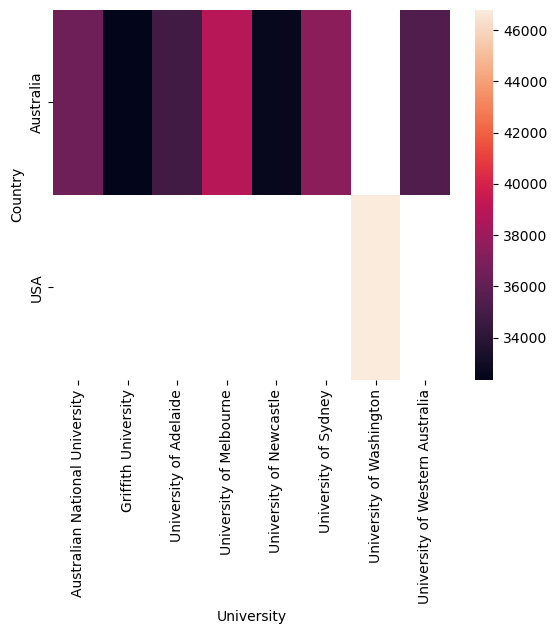

In [56]:
sns.heatmap(data)

## feauture engineering 
# feature selction -- selcting best feature-- mention all column names inside a list

In [57]:
df.head()

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate
0,USA,Cambridge,Harvard University,Computer Science,Master,2.0,55400,83.5,2200,160,1500,1.00
1,UK,London,Imperial College London,Data Science,Master,1.0,41200,75.8,1800,485,800,0.79
2,Canada,Toronto,University of Toronto,Business Analytics,Master,2.0,38500,72.5,1600,235,900,1.35
3,Australia,Melbourne,University of Melbourne,Engineering,Master,2.0,42000,71.2,1400,450,650,1.52
4,Germany,Munich,Technical University of Munich,Mechanical Engineering,Master,2.0,500,70.5,1100,75,550,0.92


In [58]:
df['Total_cost']=df['Tuition_USD'] + df['Rent_USD']

In [59]:
df.head()

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate,Total_cost
0,USA,Cambridge,Harvard University,Computer Science,Master,2.0,55400,83.5,2200,160,1500,1.00,57600
1,UK,London,Imperial College London,Data Science,Master,1.0,41200,75.8,1800,485,800,0.79,43000
2,Canada,Toronto,University of Toronto,Business Analytics,Master,2.0,38500,72.5,1600,235,900,1.35,40100
3,Australia,Melbourne,University of Melbourne,Engineering,Master,2.0,42000,71.2,1400,450,650,1.52,43400
4,Germany,Munich,Technical University of Munich,Mechanical Engineering,Master,2.0,500,70.5,1100,75,550,0.92,1600


In [60]:
df=df[['Country','City','University','Program','Level','Duration_Years','Living_Cost_Index','Visa_Fee_USD','Insurance_USD','Total_cost']]

In [61]:
df.head()

,Country,City,University,Program,Level,Duration_Years,Living_Cost_Index,Visa_Fee_USD,Insurance_USD,Total_cost
0,USA,Cambridge,Harvard University,Computer Science,Master,2.0,83.5,160,1500,57600
1,UK,London,Imperial College London,Data Science,Master,1.0,75.8,485,800,43000
2,Canada,Toronto,University of Toronto,Business Analytics,Master,2.0,72.5,235,900,40100
3,Australia,Melbourne,University of Melbourne,Engineering,Master,2.0,71.2,450,650,43400
4,Germany,Munich,Technical University of Munich,Mechanical Engineering,Master,2.0,70.5,75,550,1600


In [62]:
from sklearn.preprocessing import LabelEncoder

In [63]:
le=LabelEncoder()

In [64]:
df['Country']=le.fit_transform(df['Country'])

In [65]:
df.head()

,Country,City,University,Program,Level,Duration_Years,Living_Cost_Index,Visa_Fee_USD,Insurance_USD,Total_cost
0,66,Cambridge,Harvard University,Computer Science,Master,2.0,83.5,160,1500,57600
1,65,London,Imperial College London,Data Science,Master,1.0,75.8,485,800,43000
2,9,Toronto,University of Toronto,Business Analytics,Master,2.0,72.5,235,900,40100
3,2,Melbourne,University of Melbourne,Engineering,Master,2.0,71.2,450,650,43400
4,22,Munich,Technical University of Munich,Mechanical Engineering,Master,2.0,70.5,75,550,1600


In [66]:
df['City']=le.fit_transform(df['City'])

In [67]:
df['University']=le.fit_transform(df['University'])
df['Program']=le.fit_transform(df['Program'])
df['Level']=le.fit_transform(df['Level'])


In [68]:
df.head()

,Country,City,University,Program,Level,Duration_Years,Living_Cost_Index,Visa_Fee_USD,Insurance_USD,Total_cost
0,66,84,101,17,1,2.0,83.5,160,1500,57600
1,65,283,128,27,1,1.0,75.8,485,800,43000
2,9,503,572,9,1,2.0,72.5,235,900,40100
3,2,313,495,44,1,2.0,71.2,450,650,43400
4,22,330,307,66,1,2.0,70.5,75,550,1600


In [69]:
x=df.iloc[:,:9]
y=df['Total_cost']

In [70]:
x

,Country,City,University,Program,Level,Duration_Years,Living_Cost_Index,Visa_Fee_USD,Insurance_USD
0,66,84,101,17,1,2.0,83.5,160,1500
1,65,283,128,27,1,1.0,75.8,485,800
2,9,503,572,9,1,2.0,72.5,235,900
3,2,313,495,44,1,2.0,71.2,450,650
4,22,330,307,66,1,2.0,70.5,75,550
...,...,...,...,...,...,...,...,...,...
902,21,469,556,25,1,2.0,70.2,99,850
903,38,344,345,17,0,3.0,50.5,120,400
904,51,12,154,57,1,2.0,64.2,200,800
905,66,441,585,84,2,5.0,77.8,160,1500


In [71]:
y

0      57600
1      43000
2      40100
3      43400
4       1600
       ...  
902     5000
903     7200
904     4800
905    52000
906    34800
Name: Total_cost, Length: 907, dtype: int32

In [72]:
from sklearn.preprocessing import StandardScaler


In [73]:
s=StandardScaler()

In [74]:
x=StandardScaler(x)

TypeError: StandardScaler.__init__() takes 1 positional argument but 2 were given

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
x_train.shape


(725, 9)

In [ ]:
x_test.shape

(182, 9)

In [ ]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()

In [ ]:
lr.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [ ]:
y_predict=lr.predict(x_test)

In [ ]:
## evaluation metrics--- MEA,MSE,RMSE

In [ ]:
from sklearn.metrics import mean_absolute_error

In [ ]:
mean_absolute_error(y_test,y_predict)

8659.427341273538

In [ ]:
from sklearn.metrics import mean_squared_error

In [ ]:
mean_squared_error(y_test,y_predict)

130433373.64519882

In [ ]:
## ridge regression

In [ ]:
from sklearn.linear_model import Ridge
r=Ridge(alpha=1.0)

In [ ]:
r.fit(x_train,y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [ ]:
y_predict=r.predict(x_test)

In [ ]:
mean_absolute_error(y_test,y_predict)

8659.430791591045

In [ ]:
from sklearn.linear_model import Lasso
l=Lasso(alpha=0.5)

In [ ]:
l.fit(x_train,y_train)

,alpha,0.5
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [ ]:
mean_absolute_error(y_test,y_predict)

8659.35391878815

## decision tree regressor

In [ ]:
from sklearn.tree import DecisionTreeRegressor
tree=DecisionTreeRegressor(max_depth =5)

In [ ]:
tree.fit(x_train,y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [ ]:
y_predict=tree.predict(x_test)

In [ ]:
mean_absolute_error(y_test,y_predict)

4136.742081363999

In [ ]:
## RandomForest regressor--- ensemble learning technique--- come up with  combinaton of multiple models or algo

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
forest=RandomForestRegressor(n_estimators =100)

In [ ]:
forest.fit(x_train,y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [ ]:
y_predict=forest.predict(x_test)

In [ ]:
mean_absolute_error(y_test,y_predict)

2653.5020146520146

## ensemble learning ---
# 1. XGBoost regressor
# 2. AdaBoost regressor
# 3. CatBoost regressor

In [ ]:
from sklearn.ensemble import AdaBoostRegressor

In [ ]:
ada=AdaBoostRegressor(n_estimators=100)

In [ ]:
ada.fit(x_train,y_train)

,estimator,None
,n_estimators,100
,learning_rate,1.0
,loss,'linear'
,random_state,None


In [ ]:
y_predict=ada.predict(x_test)

In [ ]:
mean_absolute_error(y_test,y_predict)

6075.02394226376

In [ ]:
from xgboost import XGBRegressor

ModuleNotFoundError: No module named 'xgboost'

In [ ]:
pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   - -------------------------------------- 2.1/48.9 MB 11.2 MB/s eta 0:00:05
   ---- ----------------------------------- 5.0/48.9 MB 10.8 MB/s eta 0:00:05
   ------ --------------------------------- 8.1/48.9 MB 11.3 MB/s eta 0:00:04
   -------- ------------------------------- 10.5/48.9 MB 11.4 MB/s eta 0:00:04
   ---------- ----------------------------- 13.1/48.9 MB 11.5 MB/s eta 0:00:04
   ------------ --------------------------- 15.5/48.9 MB 11.5 MB/s eta 0:00:03
   -------------- ------------------------- 18.1/48.9 MB 11.6 MB/s eta 0:00:03
   ---------------- ----------------------- 20.4/48.9 MB 11.6 MB/s eta 0:00:03
   ------------------ --------------------- 23.1/48.9 MB 11.6 MB/s eta 0:00:03
   -------------------- ------------------- 25.2/48.9 MB 11.5 MB/s eta 0:00:03
   ---------------------- ----------------- 27.3/48.9 MB 11.2 MB/s eta 0:00:02
   ----------------------- ---------------- 29.4/48.9 MB 11.0 MB

In [ ]:
from xgboost import XGBRegressor

In [ ]:
xgb=XGBRegressor(n_estimators=100)

In [ ]:
xgb.fit(x_train,y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [ ]:
y_predict=xgb.predict(x_test)

In [ ]:
mean_absolute_error(y_test,y_predict)

2086.75830078125

In [ ]:
## CATBoost is another similat lib right xgb
## install it seperatly and all methods are same

## K neighbours regression

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

In [ ]:
K=KNeighborsRegressor(n_neighbors =5)

In [ ]:
K.fit(x_train,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [ ]:
y_predict=K.predict(x_test)

In [ ]:
mean_absolute_error(y_test,y_predict)

5767.736263736264

## support vector machine

In [ ]:
from sklearn.svm import SVR
svr=SVR(kernel='rbf')

In [ ]:
from xgboost import XGBRegressor

,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,1.0
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


## Bagging regressor---- ensemble learning

In [ ]:
from sklearn.ensemble import BaggingRegressor
bag=BaggingRegressor(n_estimators =100)

In [ ]:
bag.fit(x_train,y_train)
y_predict=bag.predict(x_test)

In [ ]:
mean_absolute_error(y_test,y_predict)

2594.166483516484

## stacking regressor--- ensemble leanring-- combination of multiple models of our own choice

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import StackingRegressor
from sklearn.ensemble import BaggingRegressor

In [ ]:
estimators=[('rf',RandomForestRegressor()),('br' ,BaggingRegressor())]

In [ ]:
stack=StackingRegressor(estimators=estimators,final_estimator=DecisionTreeRegressor())

In [ ]:
stack.fit(x_train,y_train)

,estimators,"[('rf', ...), ('br', ...)]"
,final_estimator,DecisionTreeRegressor()
,cv,None
,n_jobs,None
,passthrough,False
,verbose,0
,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1


In [ ]:
st=pd.read_csv('Student Depression Dataset.csv')

In [ ]:
st

,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27896,140685,Female,27.0,Surat,Student,5.0,0.0,5.75,5.0,0.0,5-6 hours,Unhealthy,Class 12,Yes,7.0,1.0,Yes,0
27897,140686,Male,27.0,Ludhiana,Student,2.0,0.0,9.40,3.0,0.0,Less than 5 hours,Healthy,MSc,No,0.0,3.0,Yes,0
27898,140689,Male,31.0,Faridabad,Student,3.0,0.0,6.61,4.0,0.0,5-6 hours,Unhealthy,MD,No,12.0,2.0,No,0
27899,140690,Female,18.0,Ludhiana,Student,5.0,0.0,6.88,2.0,0.0,Less than 5 hours,Healthy,Class 12,Yes,10.0,5.0,No,1


In [ ]:
st.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     30000 non-null  int64  
 1   Gender                  30000 non-null  object 
 2   CGPA                    30000 non-null  float64
 3   Academic_Pressure       30000 non-null  int64  
 4   Study_Satisfaction      30000 non-null  int64  
 5   Sleep_Duration          30000 non-null  object 
 6   Dietary_Habits          30000 non-null  object 
 7   Financial_Stress        30000 non-null  int64  
 8   Study_Hours_Per_Day     30000 non-null  float64
 9   Attendance_Percentage   30000 non-null  float64
 10  Social_Hours_Per_Day    30000 non-null  float64
 11  Exercise_Days_Per_Week  30000 non-null  int64  
 12  Family_Support          30000 non-null  int64  
 13  Relationship_Status     30000 non-null  object 
 14  Internet_Usage_Hours    30000 non-null

In [ ]:
st.columns

Index(['id', 'Gender', 'Age', 'City', 'Profession', 'Academic Pressure',
       'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction',
       'Sleep Duration', 'Dietary Habits', 'Degree',
       'Have you ever had suicidal thoughts ?', 'Work/Study Hours',
       'Financial Stress', 'Family History of Mental Illness', 'Depression'],
      dtype='object')

In [ ]:
st=st[['Gender', 'Age', 'City', 'Profession', 'Academic Pressure',
   'CGPA', 'Study Satisfaction', 
       'Sleep Duration', 'Dietary Habits', 'Work/Study Hours',
       'Financial Stress', 'Family History of Mental Illness', 'Depression'
    
]]

## label encoding

In [ ]:
from sklearn.preprocessing import LabelEncoder
l=LabelEncoder


In [ ]:
st['Gender']=l.fit_transform(st['Gender'])

TypeError: LabelEncoder.fit_transform() missing 1 required positional argument: 'y'

In [ ]:
from sklearn.preprocessing import LabelEncoder

l = LabelEncoder()

st['Gender'] = l.fit_transform(st['Gender'])

C:\Users\sushr\AppData\Local\Temp\ipykernel_16320\3774768205.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  st['Gender'] = l.fit_transform(st['Gender'])


In [ ]:
st.head()

,Gender,Age,City,Profession,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,1,33.0,Visakhapatnam,Student,5.0,8.97,2.0,5-6 hours,Healthy,3.0,1.0,No,1
1,0,24.0,Bangalore,Student,2.0,5.90,5.0,5-6 hours,Moderate,3.0,2.0,Yes,0
2,1,31.0,Srinagar,Student,3.0,7.03,5.0,Less than 5 hours,Healthy,9.0,1.0,Yes,0
3,0,28.0,Varanasi,Student,3.0,5.59,2.0,7-8 hours,Moderate,4.0,5.0,Yes,1
4,0,25.0,Jaipur,Student,4.0,8.13,3.0,5-6 hours,Moderate,1.0,1.0,No,0


In [ ]:
st['City']=l.fit_transform(st['City'])

C:\Users\sushr\AppData\Local\Temp\ipykernel_16320\709463881.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  st['City']=l.fit_transform(st['City'])


In [ ]:
st['Profession']=l.fit_transform(st['Profession'])
st['Sleep Duration']=l.fit_transform(st['Sleep Duration'])
st['Dietary Habits']=l.fit_transform(st['Dietary Habits'])
st['Family History of Mental Illness']=l.fit_transform(st['Family History of Mental Illness'])


C:\Users\sushr\AppData\Local\Temp\ipykernel_16320\3667441095.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  st['Profession']=l.fit_transform(st['Profession'])
C:\Users\sushr\AppData\Local\Temp\ipykernel_16320\3667441095.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  st['Sleep Duration']=l.fit_transform(st['Sleep Duration'])
C:\Users\sushr\AppData\Local\Temp\ipykernel_16320\3667441095.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[ro

In [ ]:
st.head()

,Gender,Age,City,Profession,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,1,33.0,51,11,5.0,8.97,2.0,0,0,3.0,1.0,0,1
1,0,24.0,3,11,2.0,5.90,5.0,0,1,3.0,2.0,1,0
2,1,31.0,44,11,3.0,7.03,5.0,2,0,9.0,1.0,1,0
3,0,28.0,49,11,3.0,5.59,2.0,1,1,4.0,5.0,1,1
4,0,25.0,16,11,4.0,8.13,3.0,0,1,1.0,1.0,0,0


In [ ]:
st.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 13 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Gender                            27901 non-null  int64  
 1   Age                               27901 non-null  float64
 2   City                              27901 non-null  int64  
 3   Profession                        27901 non-null  int64  
 4   Academic Pressure                 27901 non-null  float64
 5   CGPA                              27901 non-null  float64
 6   Study Satisfaction                27901 non-null  float64
 7   Sleep Duration                    27901 non-null  int64  
 8   Dietary Habits                    27901 non-null  int64  
 9   Work/Study Hours                  27901 non-null  float64
 10  Financial Stress                  27898 non-null  float64
 11  Family History of Mental Illness  27901 non-null  int64  
 12  Depr

In [ ]:
st['Family History of Mental Illness']=st['Family History of Mental Illness'].astype('float32')

C:\Users\sushr\AppData\Local\Temp\ipykernel_16320\1857149422.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  st['Family History of Mental Illness']=st['Family History of Mental Illness'].astype('float32')


In [ ]:
st.columns

Index(['Gender', 'Age', 'City', 'Profession', 'Academic Pressure', 'CGPA',
       'Study Satisfaction', 'Sleep Duration', 'Dietary Habits',
       'Work/Study Hours', 'Financial Stress',
       'Family History of Mental Illness', 'Depression'],
      dtype='object')

## seperate input and output data

In [ ]:
x=st[['Gender', 'Age', 'City', 'Profession', 'Academic Pressure', 'CGPA',
       'Study Satisfaction', 'Sleep Duration', 'Dietary Habits',
       'Work/Study Hours', 'Financial Stress',
       'Family History of Mental Illness']]

In [ ]:
y=st[['Depression']]

In [ ]:
## feature scaling

In [ ]:
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()

In [ ]:
x=ss.fit_transform(x)
y=ss.fit_transform(y)

In [ ]:
x

array([[ 0.89137266,  1.46320131,  1.51052261, ..., -1.12111524,
        -1.48878834, -0.96838258],
       [-1.12186524, -0.37145045, -1.42420578, ..., -1.12111524,
        -0.79304951,  1.03264972],
       [ 0.89137266,  1.05550092,  1.08254139, ...,  0.49721209,
        -1.48878834,  1.03264972],
       ...,
       [ 0.89137266,  1.05550092, -1.05736473, ...,  1.30637576,
        -0.79304951, -0.96838258],
       [-1.12186524, -1.59455162, -0.07912193, ...,  0.76693332,
         1.29416701, -0.96838258],
       [ 0.89137266,  0.24010013,  0.71570034, ..., -1.39083646,
        -0.09731067,  1.03264972]], shape=(27898, 12))

In [ ]:

y

array([[ 0.84134805],
       [-1.18856875],
       [-1.18856875],
       ...,
       [-1.18856875],
       [ 0.84134805],
       [ 0.84134805]], shape=(27898, 1))

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
x_train.shape

(22318, 12)

## logistic regression

In [ ]:
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression()

In [ ]:
x_train

array([[ 0.89141615,  0.44392122,  1.38824107, ..., -0.85149541,
        -1.48878834,  1.03260911],
       [-1.1218105 ,  1.46316463,  0.71569429, ...,  1.30624884,
         0.59842817,  1.03260911],
       [-1.1218105 ,  1.46316463, -0.62939927, ...,  1.30624884,
        -0.09731067, -0.96842067],
       ...,
       [ 0.89141615, -1.5945656 , -0.32369619, ..., -0.31205934,
         1.29416701,  1.03260911],
       [-1.1218105 , -1.5945656 , -1.24080543, ..., -1.93036753,
        -0.09731067,  1.03260911],
       [ 0.89141615,  1.66701331,  1.14367861, ..., -0.58177738,
         0.59842817, -0.96842067]], shape=(22320, 12))

In [ ]:
st = st.dropna()

In [ ]:
import numpy as np

In [ ]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean')

x_train = imputer.fit_transform(x_train)
x_test = imputer.transform(x_test)

In [ ]:
print(y_train[:10])
print(y_train.dtype)
print(np.unique(y_train))

[[-1.18850235]
 [-1.18850235]
 [ 0.84139506]
 [-1.18850235]
 [ 0.84139506]
 [ 0.84139506]
 [ 0.84139506]
 [-1.18850235]
 [-1.18850235]
 [ 0.84139506]]
float64
[-1.18850235  0.84139506]


In [ ]:
x_train = ss.fit_transform(x_train)
x_test = ss.transform(x_test)

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [ ]:
x_train = ss.fit_transform(x_train)
x_test = ss.fit_transform(x_test)

In [ ]:
import pandas as pd

In [ ]:
import numpy as np

print(np.isnan(x_train).sum())

3


In [ ]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean')

x_train = imputer.fit_transform(x_train)
x_test = imputer.transform(x_test)

In [ ]:
print(np.isnan(x_train).sum())
print(np.isnan(x_test).sum())

0
0


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [ ]:
sc = StandardScaler()

x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
tree=DecisionTreeClassifier()

In [ ]:
import numpy as np

print(y_train.dtype)
print(y_train.shape)
print(len(np.unique(y_train)))   # number of distinct values
print(y_train[:10])              # first 10 values

float64
(22320, 1)
2
[[-1.18850235]
 [-1.18850235]
 [ 0.84139506]
 [-1.18850235]
 [ 0.84139506]
 [ 0.84139506]
 [ 0.84139506]
 [-1.18850235]
 [-1.18850235]
 [ 0.84139506]]


In [ ]:
import numpy as np

# map the smaller value to 0 and the larger to 1
vals = np.unique(y_train)          # sorted: [-1.1885, 0.8414]
y_train = (y_train.ravel() == vals[1]).astype(int)

# apply the SAME mapping to y_test (don't recompute from y_test)
y_test = (y_test.ravel() == vals[1]).astype(int)

In [ ]:
tree.fit(x_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [ ]:
y_predict=tree.predict(x_test)

In [ ]:
from sklearn.metrics import accuracy_score

In [ ]:
accuracy_score(y_test, y_predict)

0.6962909872782655

## random forest classifier

In [ ]:
from sklearn.ensemble import RandomForestClassifier
forest=RandomForestClassifier(n_estimators=100)

In [ ]:
forest.fit(x_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [ ]:
y_predict=forest.predict(x_test)


In [ ]:
accuracy_score(y_test, y_predict)

0.7846264110374485

In [ ]:
from sklearn.naive_bayes import BernoulliNB
bn=BernoulliNB()

In [ ]:
import numpy as np

# map the smaller value to 0 and the larger to 1
vals = np.unique(y_train)          # sorted: [-1.1885, 0.8414]
y_train = (y_train.ravel() == vals[1]).astype(int)

# apply the SAME mapping to y_test (don't recompute from y_test)
y_test = (y_test.ravel() == vals[1]).astype(int)

In [ ]:
print(df.isnull().sum())

Country              0
City                 0
University           0
Program              0
Level                0
Duration_Years       0
Living_Cost_Index    0
Visa_Fee_USD         0
Insurance_USD        0
Total_cost           0
dtype: int64


In [ ]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")   # or "most_frequent" for categorical-like columns
x_train = imputer.fit_transform(x_train)     # fit on train only
x_test = imputer.transform(x_test)

bn.fit(x_train, y_train)

,alpha,1.0
,force_alpha,True
,binarize,0.0
,fit_prior,True
,class_prior,None


In [ ]:
train_mask = ~np.isnan(x_train).any(axis=1)
x_train = x_train[train_mask]
y_train = np.ravel(y_train)[train_mask]

test_mask = ~np.isnan(x_test).any(axis=1)
x_test = x_test[test_mask]
y_test = np.ravel(y_test)[test_mask]

In [ ]:
from sklearn.naive_bayes import MultinomialNB
mn=MultinomialNB()

## hyper parameter tuning-- gridsearchcv or randomsearchcv

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [4, 6, 8]
}

grid=GridSearchCV(RandomForestRegressor(),param_grid,cv=5)

In [ ]:
print(grid.best_params_)
print(grid.best_score_)

In [ ]:
from sklearn.ensemble import RandomForestRegressor
RandomForestRegressor()
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import StackingRegressor

est

In [ ]:
from sklearn.ensemble import RandomForestRegressor
model=RandomForestRegressor(n_estimators=200)

In [ ]:
model.fit(x_train, y_train)

,n_estimators,200
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [ ]:
y_predict=model.predict(x_test)

In [ ]:
mean_absolute_error(y_test,y_predict)

2626.732692307692

In [ ]:
import pickle
with open('model.pkl','wb') as file:
    pickle.dump(model,file)

In [ ]:
with open('model.pkl','rb') as file:
    new_model=pickle.load(file)

In [ ]:
new_model

,n_estimators,200
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [ ]:
new_model.predict(IIT bombay)

SyntaxError: invalid syntax. Perhaps you forgot a comma? (3895668144.py, line 1)

In [ ]:
import joblib
import pandas as pd

model = joblib.load("model.pkl")
     # dict of your LabelEncoders
# scaler = joblib.load("scaler.pkl")        # only if you scaled x

new_data = pd.DataFrame({
    "University": ["MIT"],                  # use your real column names
    "City": ["Boston"],
    "Duration": [2],                        # any other feature columns
})

# encode text columns with the saved encoders (transform only)
for col in ["University", "City"]:
    new_data[col] = encoders[col].transform(new_data[col])

# new_data = scaler.transform(new_data)     # only if you used a scaler in training

cost = model.predict(new_data)
print("Predicted total cost:", cost[0])

NameError: name 'encoders' is not defined

In [ ]:
pip install streamlit


Note: you may need to restart the kernel to use updated packages.


In [75]:
import pandas as pd
import joblib
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# keep only what we need (no visa, no insurance)
df = df[['Country','City','University','Program','Level',
         'Duration_Years','Living_Cost_Index','Total_cost']]
df = df.dropna()
ref = df.copy()                      # readable copy (real names) for the app

cat_cols = ['Country', 'City', 'University', 'Program', 'Level']
encoders = {}
for col in cat_cols:
    encoders[col] = LabelEncoder()
    df[col] = encoders[col].fit_transform(df[col])

x = df.drop('Total_cost', axis=1)
y = df['Total_cost']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)
model.fit(x_train, y_train)
print("MAE:", mean_absolute_error(y_test, model.predict(x_test)))

joblib.dump(model, 'model.pkl', compress=3)
joblib.dump(encoders, 'encoders.pkl')
joblib.dump(list(x.columns), 'columns.pkl')
ref.to_csv('reference.csv', index=False)

MAE: 2654.715934065934


In [76]:
import streamlit as st
import pandas as pd
import joblib

model = joblib.load('model.pkl')
encoders = joblib.load('encoders.pkl')
cols = joblib.load('columns.pkl')
ref = pd.read_csv('reference.csv')

st.title("🎓 Study Abroad Cost Estimator")

country = st.selectbox("Country", sorted(ref['Country'].unique()))
d = ref[ref['Country'] == country]

city = st.selectbox("City", sorted(d['City'].unique()))
d = d[d['City'] == city]

uni = st.selectbox("University", sorted(d['University'].unique()))
d = d[d['University'] == uni]

program = st.selectbox("Program", sorted(d['Program'].unique()))
d = d[d['Program'] == program]

level = st.selectbox("Level", sorted(d['Level'].unique()))
d = d[d['Level'] == level]

if st.button("Estimate total cost"):
    row = d.iloc[[0]].drop(columns='Total_cost').copy()
    for col in encoders:
        row[col] = encoders[col].transform(row[col])
    row = row[cols]
    cost = model.predict(row)[0]
    st.success(f"Estimated total cost: ${cost:,.0f}")

2026-11-18 13:52:14.829 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 13:52:16.803 
  command:

    streamlit run C:\Users\sushr\AppData\Roaming\Python\Python313\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-18 13:52:16.806 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 13:52:16.809 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 13:52:16.813 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 13:52:16.816 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 13:52:16.819 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-18 13:52:16.824 Thre

In [1]:
import pandas as pd

raw = pd.read_csv('Education.csv')
raw['Total_cost'] = raw['Tuition_USD'].astype('int32') + raw['Rent_USD'].astype('int32')

ref = raw[['Country','City','University','Program','Level',
           'Duration_Years','Living_Cost_Index','Total_cost']].dropna()

ref.to_csv('reference.csv', index=False)
print(ref.head())

     Country       City                      University  \
0        USA  Cambridge              Harvard University   
1         UK     London         Imperial College London   
2     Canada    Toronto           University of Toronto   
3  Australia  Melbourne         University of Melbourne   
4    Germany     Munich  Technical University of Munich   

                  Program   Level  Duration_Years  Living_Cost_Index  \
0        Computer Science  Master             2.0               83.5   
1            Data Science  Master             1.0               75.8   
2      Business Analytics  Master             2.0               72.5   
3             Engineering  Master             2.0               71.2   
4  Mechanical Engineering  Master             2.0               70.5   

   Total_cost  
0       57600  
1       43000  
2       40100  
3       43400  
4        1600  


In [2]:
import pandas as pd
import joblib
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# 1. load fresh data with real names
df = pd.read_csv('Education.csv')
df['Total_cost'] = df['Tuition_USD'].astype('int32') + df['Rent_USD'].astype('int32')

df = df[['Country','City','University','Program','Level',
         'Duration_Years','Living_Cost_Index','Total_cost']].dropna()

# 2. copy BEFORE encoding (this keeps the names)
ref = df.copy()

# 3. one encoder per column
cat_cols = ['Country', 'City', 'University', 'Program', 'Level']
encoders = {}
for col in cat_cols:
    encoders[col] = LabelEncoder()
    df[col] = encoders[col].fit_transform(df[col])

# 4. train
x = df.drop('Total_cost', axis=1)
y = df['Total_cost']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)
model.fit(x_train, y_train)
print("MAE:", mean_absolute_error(y_test, model.predict(x_test)))

# 5. save everything
joblib.dump(model, 'model.pkl', compress=3)
joblib.dump(encoders, 'encoders.pkl')
joblib.dump(list(x.columns), 'columns.pkl')
ref.to_csv('reference.csv', index=False)

print(ref.head())

MAE: 2654.715934065934
     Country       City                      University  \
0        USA  Cambridge              Harvard University   
1         UK     London         Imperial College London   
2     Canada    Toronto           University of Toronto   
3  Australia  Melbourne         University of Melbourne   
4    Germany     Munich  Technical University of Munich   

                  Program   Level  Duration_Years  Living_Cost_Index  \
0        Computer Science  Master             2.0               83.5   
1            Data Science  Master             1.0               75.8   
2      Business Analytics  Master             2.0               72.5   
3             Engineering  Master             2.0               71.2   
4  Mechanical Engineering  Master             2.0               70.5   

   Total_cost  
0       57600  
1       43000  
2       40100  
3       43400  
4        1600  


In [3]:
import pandas as pd

raw = pd.read_csv('Education.csv')
raw['Tuition_USD'] = raw['Tuition_USD'].astype('int32')
raw['Rent_USD'] = raw['Rent_USD'].astype('int32')
raw['Total_cost'] = raw['Tuition_USD'] + raw['Rent_USD']

ref = raw[['Country','City','University','Program','Level',
           'Duration_Years','Living_Cost_Index',
           'Tuition_USD','Rent_USD','Total_cost']].dropna()

ref.to_csv('reference.csv', index=False)
print(ref.head())

     Country       City                      University  \
0        USA  Cambridge              Harvard University   
1         UK     London         Imperial College London   
2     Canada    Toronto           University of Toronto   
3  Australia  Melbourne         University of Melbourne   
4    Germany     Munich  Technical University of Munich   

                  Program   Level  Duration_Years  Living_Cost_Index  \
0        Computer Science  Master             2.0               83.5   
1            Data Science  Master             1.0               75.8   
2      Business Analytics  Master             2.0               72.5   
3             Engineering  Master             2.0               71.2   
4  Mechanical Engineering  Master             2.0               70.5   

   Tuition_USD  Rent_USD  Total_cost  
0        55400      2200       57600  
1        41200      1800       43000  
2        38500      1600       40100  
3        42000      1400       43400  
4          500   

In [4]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

d = pd.read_csv('reference.csv')
d = d[['Country','City','University','Program','Level',
       'Duration_Years','Living_Cost_Index','Total_cost']]

for col in ['Country','City','University','Program','Level']:
    d[col] = LabelEncoder().fit_transform(d[col])

x = d.drop('Total_cost', axis=1)
y = d['Total_cost']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42),
}

results = []
for name, m in models.items():
    m.fit(x_train, y_train)
    p = m.predict(x_test)
    results.append({"Model": name,
                    "MAE": round(mean_absolute_error(y_test, p)),
                    "R2": round(r2_score(y_test, p), 3)})

print(pd.DataFrame(results).sort_values("MAE"))

               Model    MAE     R2
2      Random Forest   2655  0.934
1      Decision Tree   3045  0.874
0  Linear Regression  12279  0.252


In [5]:
import sklearn, pandas, joblib, streamlit
print("streamlit==" + streamlit.__version__)
print("pandas==" + pandas.__version__)
print("scikit-learn==" + sklearn.__version__)
print("joblib==" + joblib.__version__)

streamlit==1.67.0
pandas==2.3.3
scikit-learn==1.7.2
joblib==1.5.2
